In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 100

In [3]:
data = pd.read_csv("dataset/ev battery_failure prediction Dataset.csv")

df_quanti = data.select_dtypes(include='number')
df_quali = data.select_dtypes(exclude='number')

In [4]:
print(data.shape)
display(df_quanti.describe().T)
display(df_quali.describe().T)

(20000, 70)


,count,mean,std,min,25%,50%,75%,max
manufacturing_year,19018.0,2019.491482,2.864259,2015.000,2017.0000,2019.0000,2022.0000,2024.000
battery_capacity_kwh,19310.0,87.124810,35.831323,25.000,56.0500,87.3150,118.3000,149.010
odometer_km,19134.0,169562.067362,74761.687034,500.000,116105.4500,158148.0000,211502.9000,450000.000
vehicle_age_years,19232.0,6.507302,2.882844,1.370,4.0000,6.5200,8.9900,11.550
cycle_count,19234.0,1358.999584,529.597491,173.000,984.0000,1295.0000,1658.0000,3369.000
battery_health_percent,19102.0,81.911451,8.991068,47.030,75.9700,82.9300,88.8200,99.800
state_of_charge,19036.0,50.940556,28.290460,2.000,26.3500,50.7600,75.4900,100.000
depth_of_discharge,19168.0,44.429334,17.035009,5.230,31.4400,43.8100,56.9625,90.340
state_of_health,19044.0,81.881542,9.108197,47.770,75.8000,82.8800,88.8225,100.000
cell_voltage_avg,19060.0,3.597902,0.126524,3.061,3.5130,3.6000,3.6870,3.850


,count,unique,top,freq
vehicle_id,20000,20000,EV100000,1
vehicle_brand,19356,20,BYD,1007
vehicle_model,19180,42,Air,954
vehicle_type,19356,6,Hatchback,3266
battery_manufacturer,19382,8,Panasonic,2505
battery_chemistry,19278,5,NMC,7576
drive_type,19274,3,AWD,6469
fleet_or_private,19106,2,Private,12358
battery_serial,20000,20000,BAT-10000000,1
terrain_type,19288,5,Coastal,3899


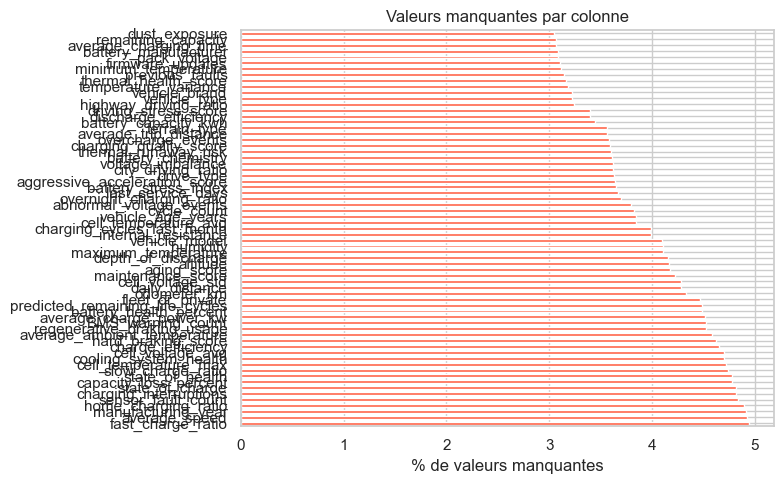

In [5]:
missing = data.isna().mean().sort_values(ascending=False)
missing = missing[missing > 0] * 100

plt.figure(figsize=(8, 5))
missing.plot(kind='barh', color='tomato')
plt.xlabel('% de valeurs manquantes')
plt.title('Valeurs manquantes par colonne')
plt.tight_layout()
plt.show()

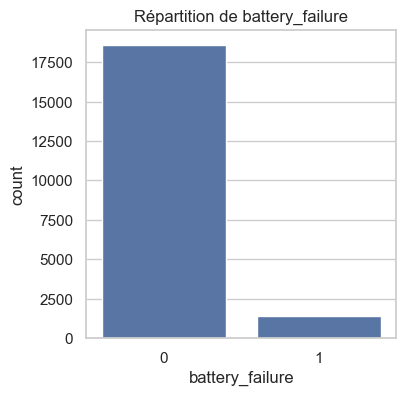

battery_failure
0    0.931
1    0.069
Name: proportion, dtype: float64


In [6]:
plt.figure(figsize=(4, 4))
sns.countplot(data=data, x='battery_failure')
plt.title('Répartition de battery_failure')
plt.show()
print(data['battery_failure'].value_counts(normalize=True).round(3))

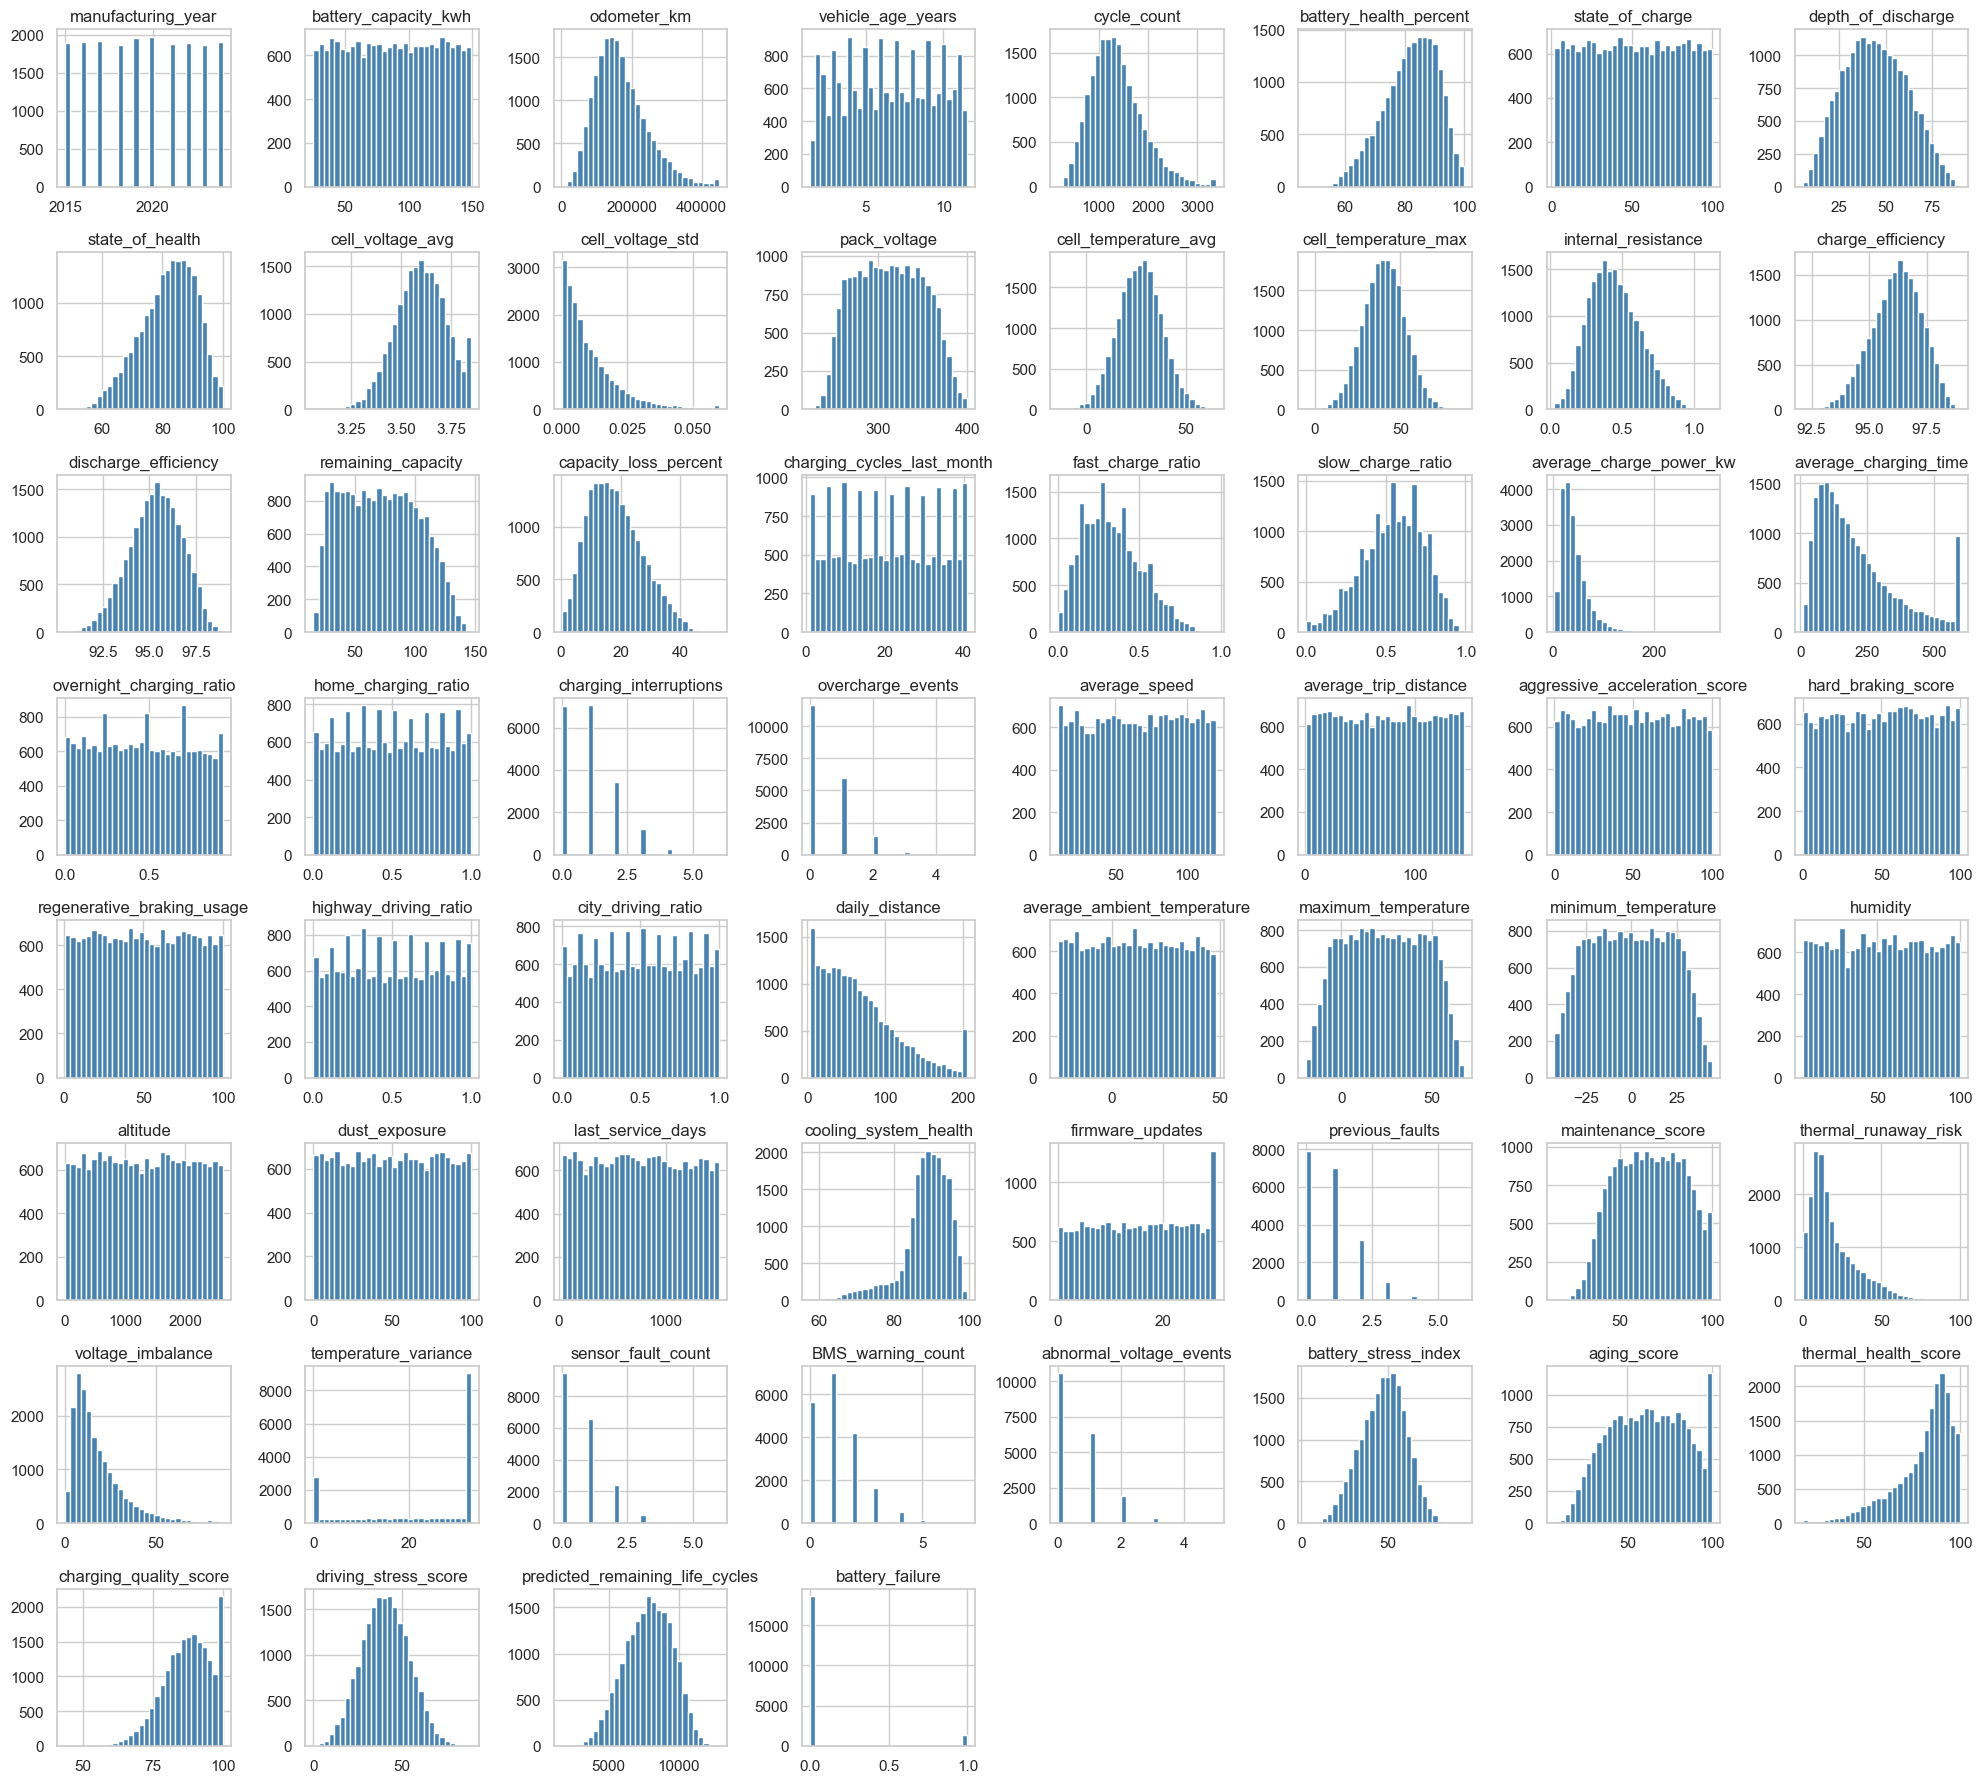

In [7]:
df_quanti.hist(bins=30, figsize=(20, 18), color='steelblue', edgecolor='white')
plt.tight_layout()
plt.show()

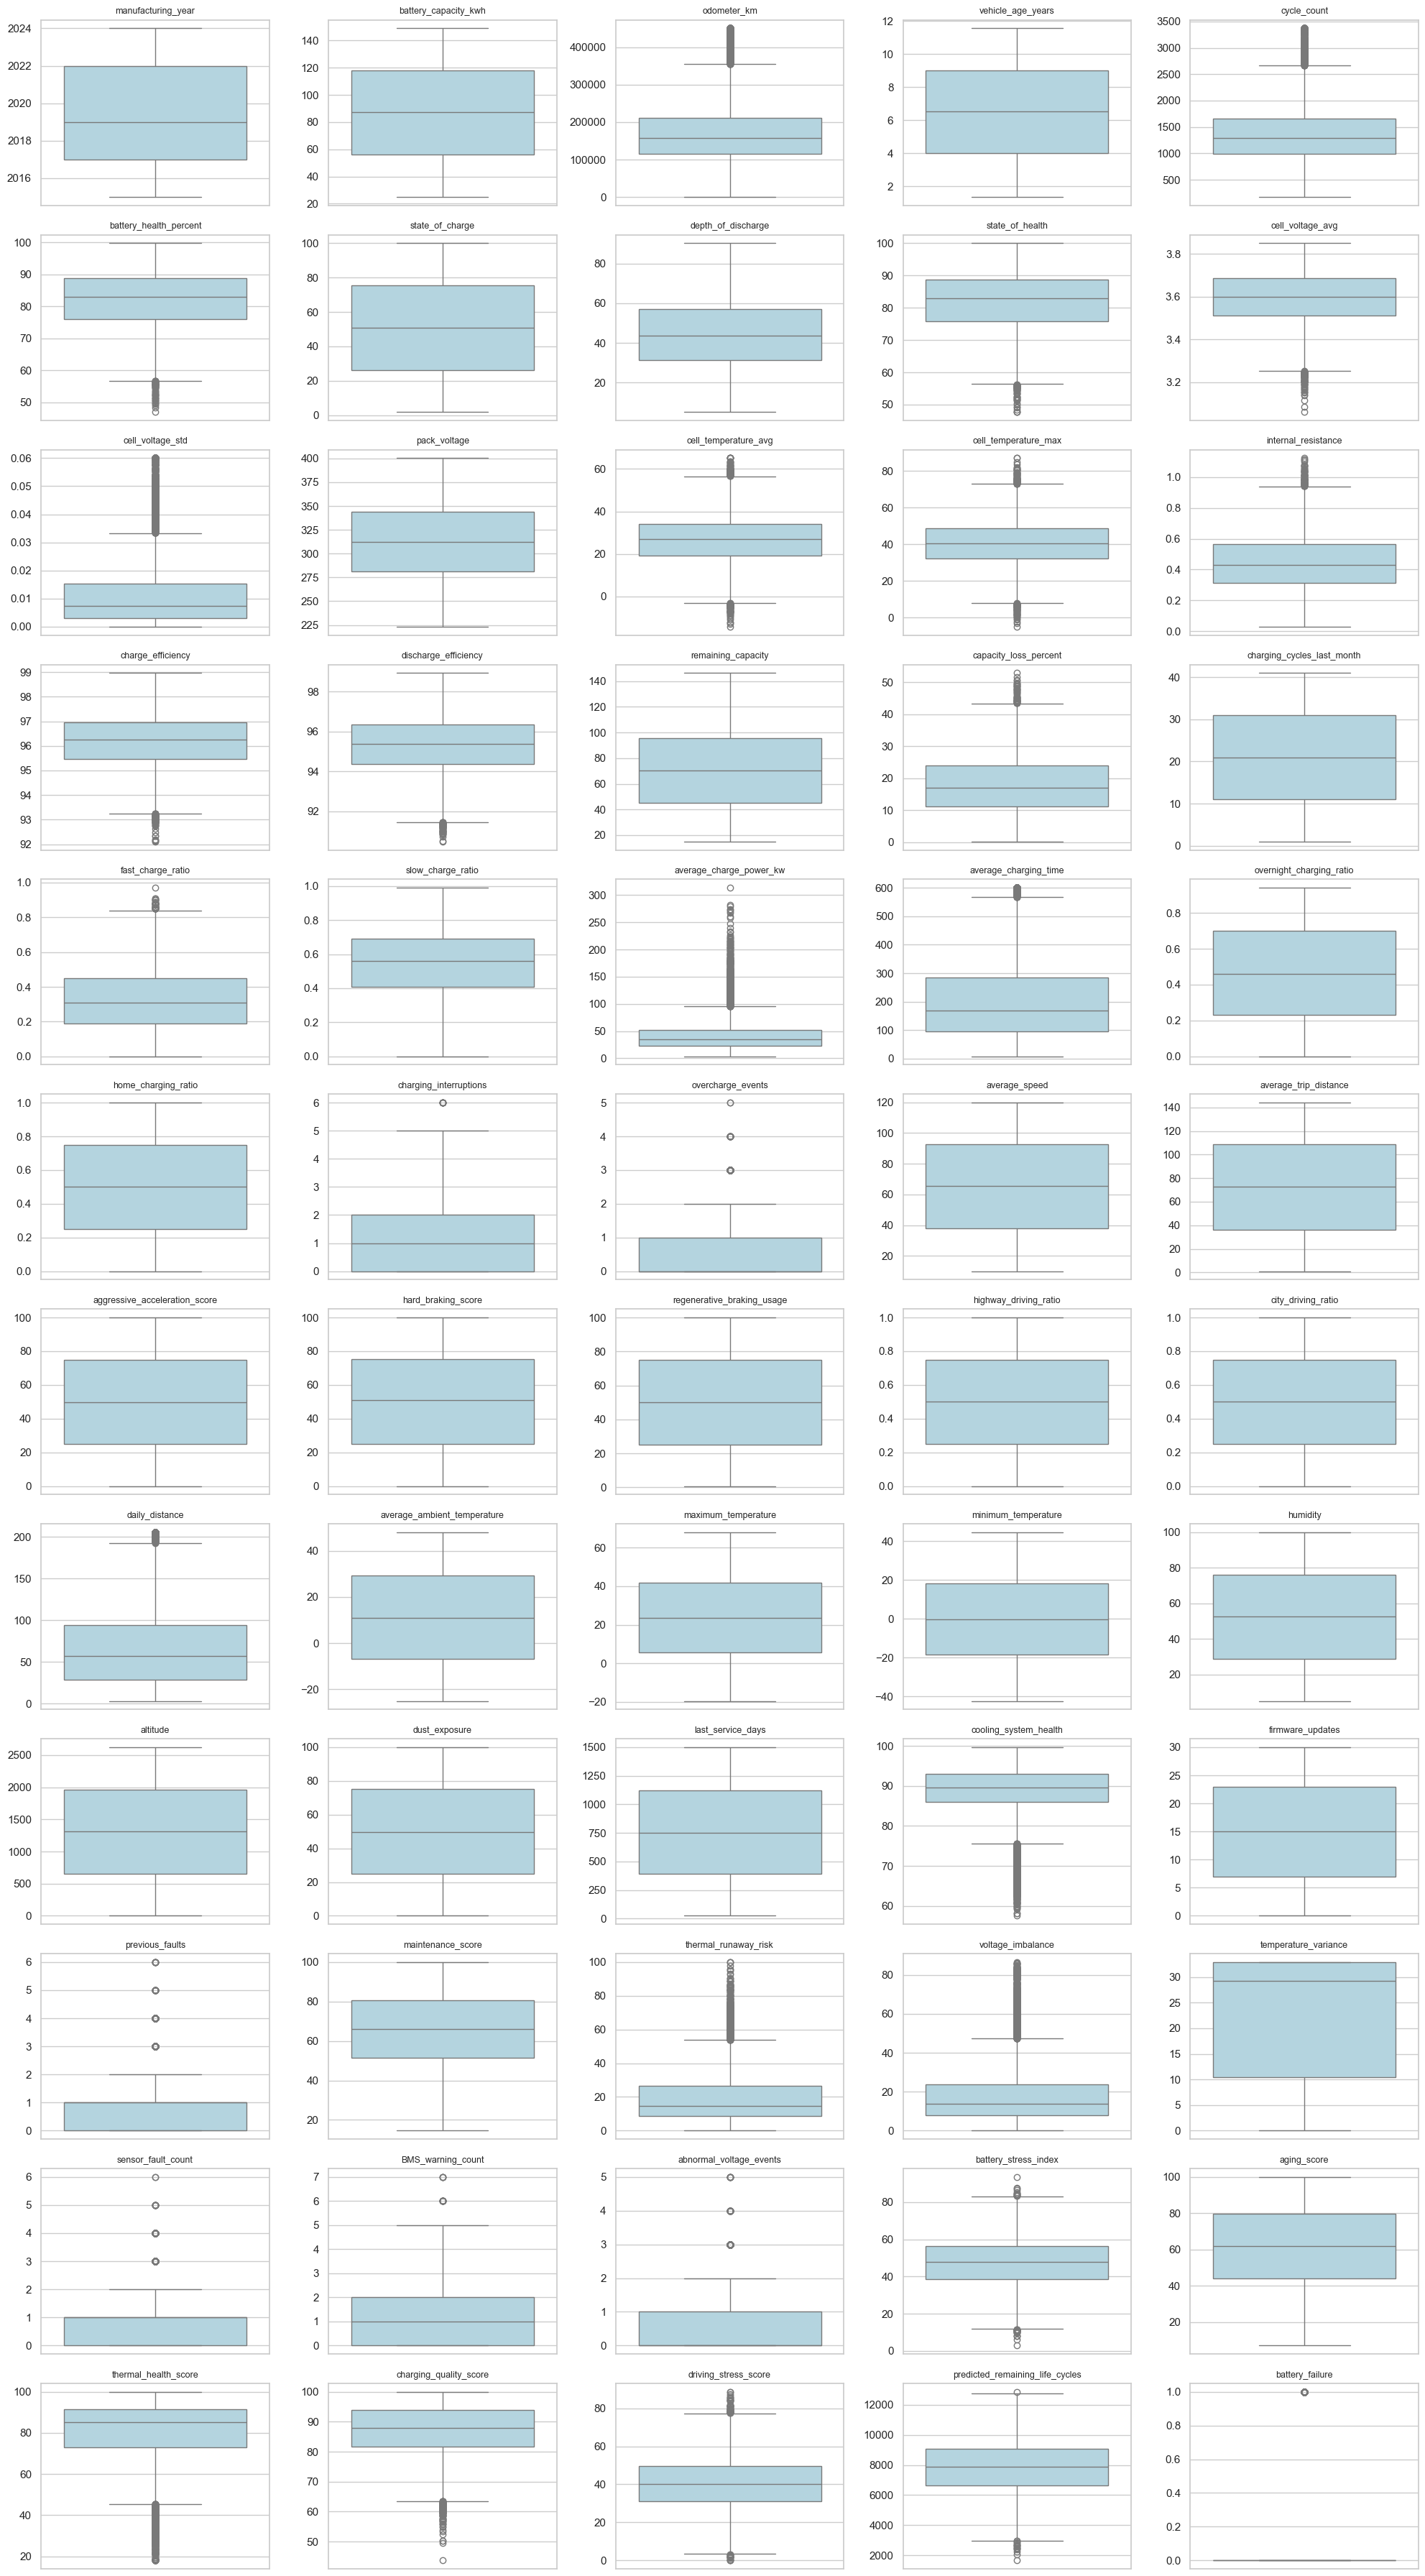

In [8]:
cols = df_quanti.columns
n_cols = 5
n_rows = int(np.ceil(len(cols) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 3 * n_rows))
for ax, col in zip(axes.flat, cols):
    sns.boxplot(y=df_quanti[col], ax=ax, color='lightblue')
    ax.set_title(col, fontsize=9)
    ax.set_ylabel('')
for ax in axes.flat[len(cols):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

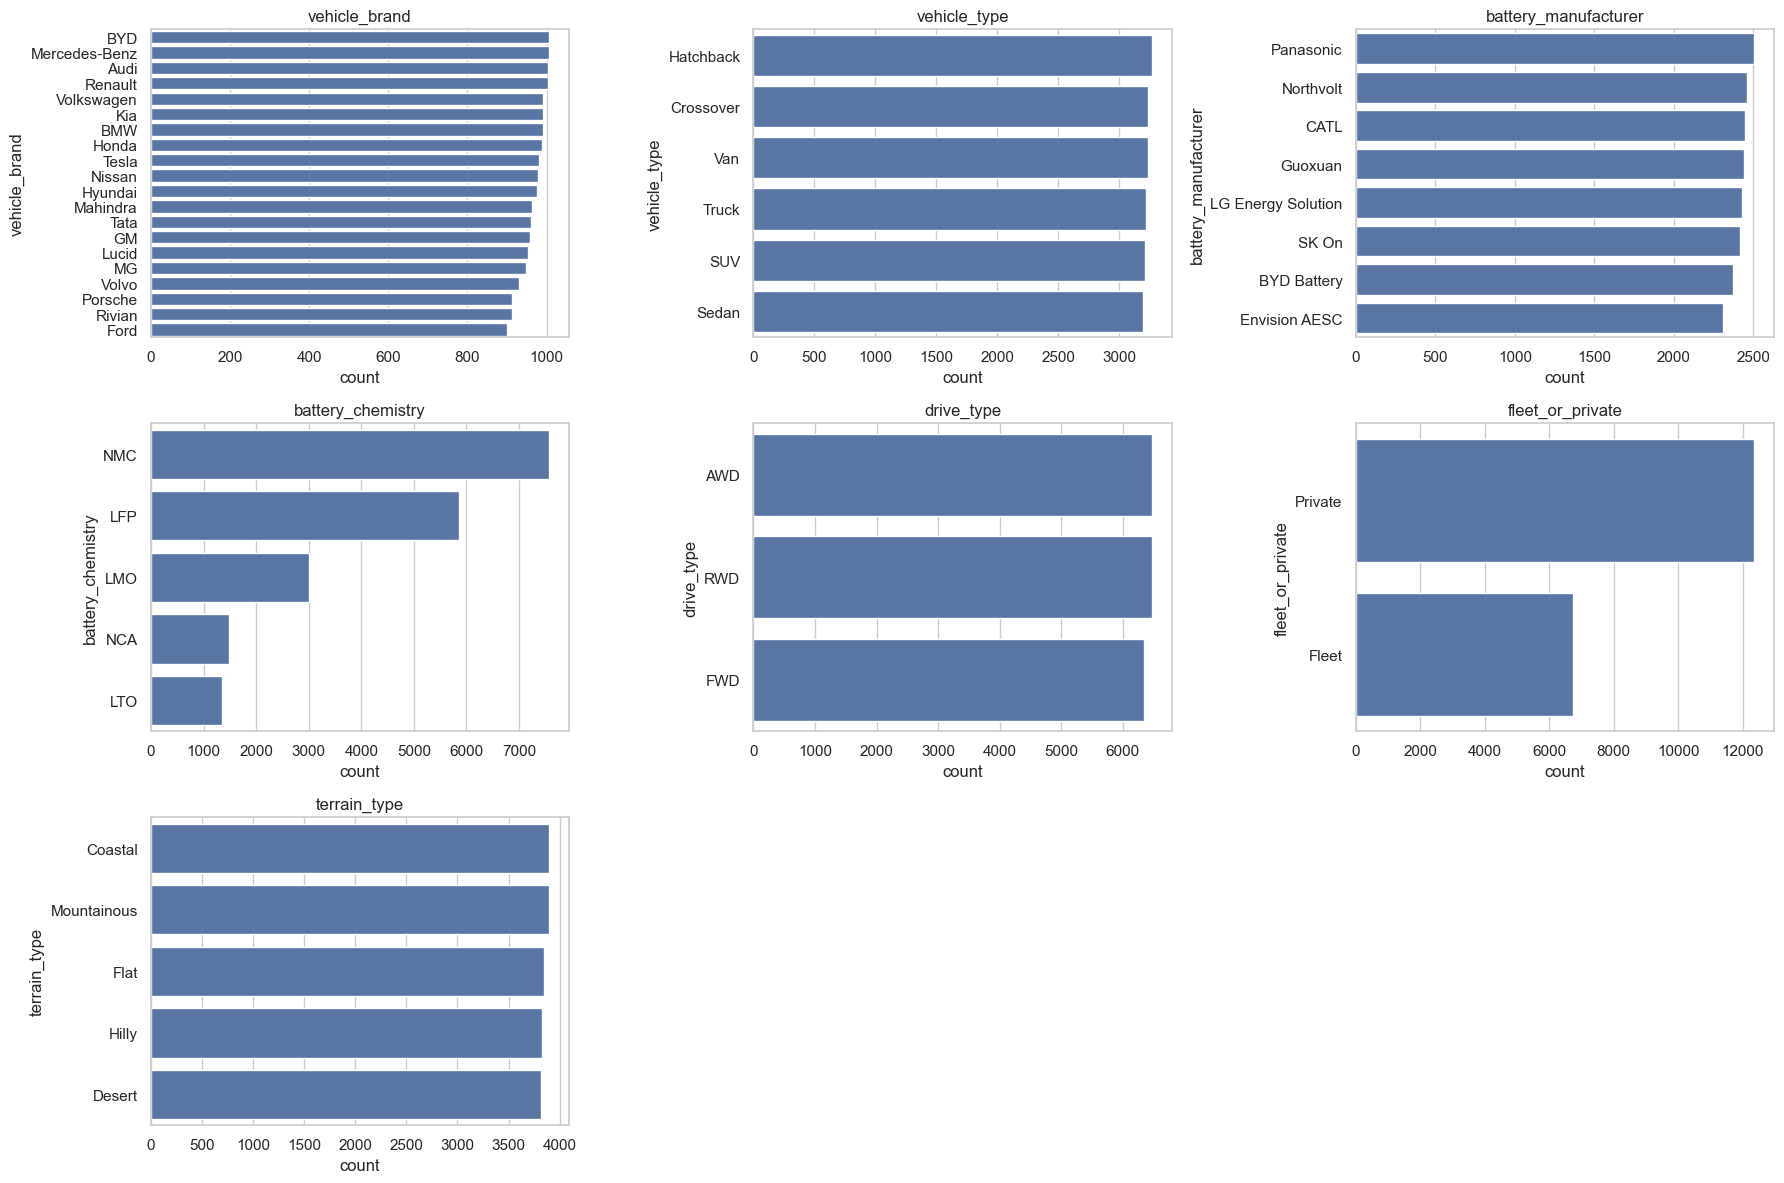

In [9]:
cols = [c for c in df_quali.columns if df_quali[c].nunique() < 30]  # évite vehicle_id, battery_serial
n_cols = 3
n_rows = int(np.ceil(len(cols) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows))
for ax, col in zip(axes.flat, cols):
    sns.countplot(data=data, y=col, ax=ax, order=data[col].value_counts().index)
    ax.set_title(col)
for ax in axes.flat[len(cols):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

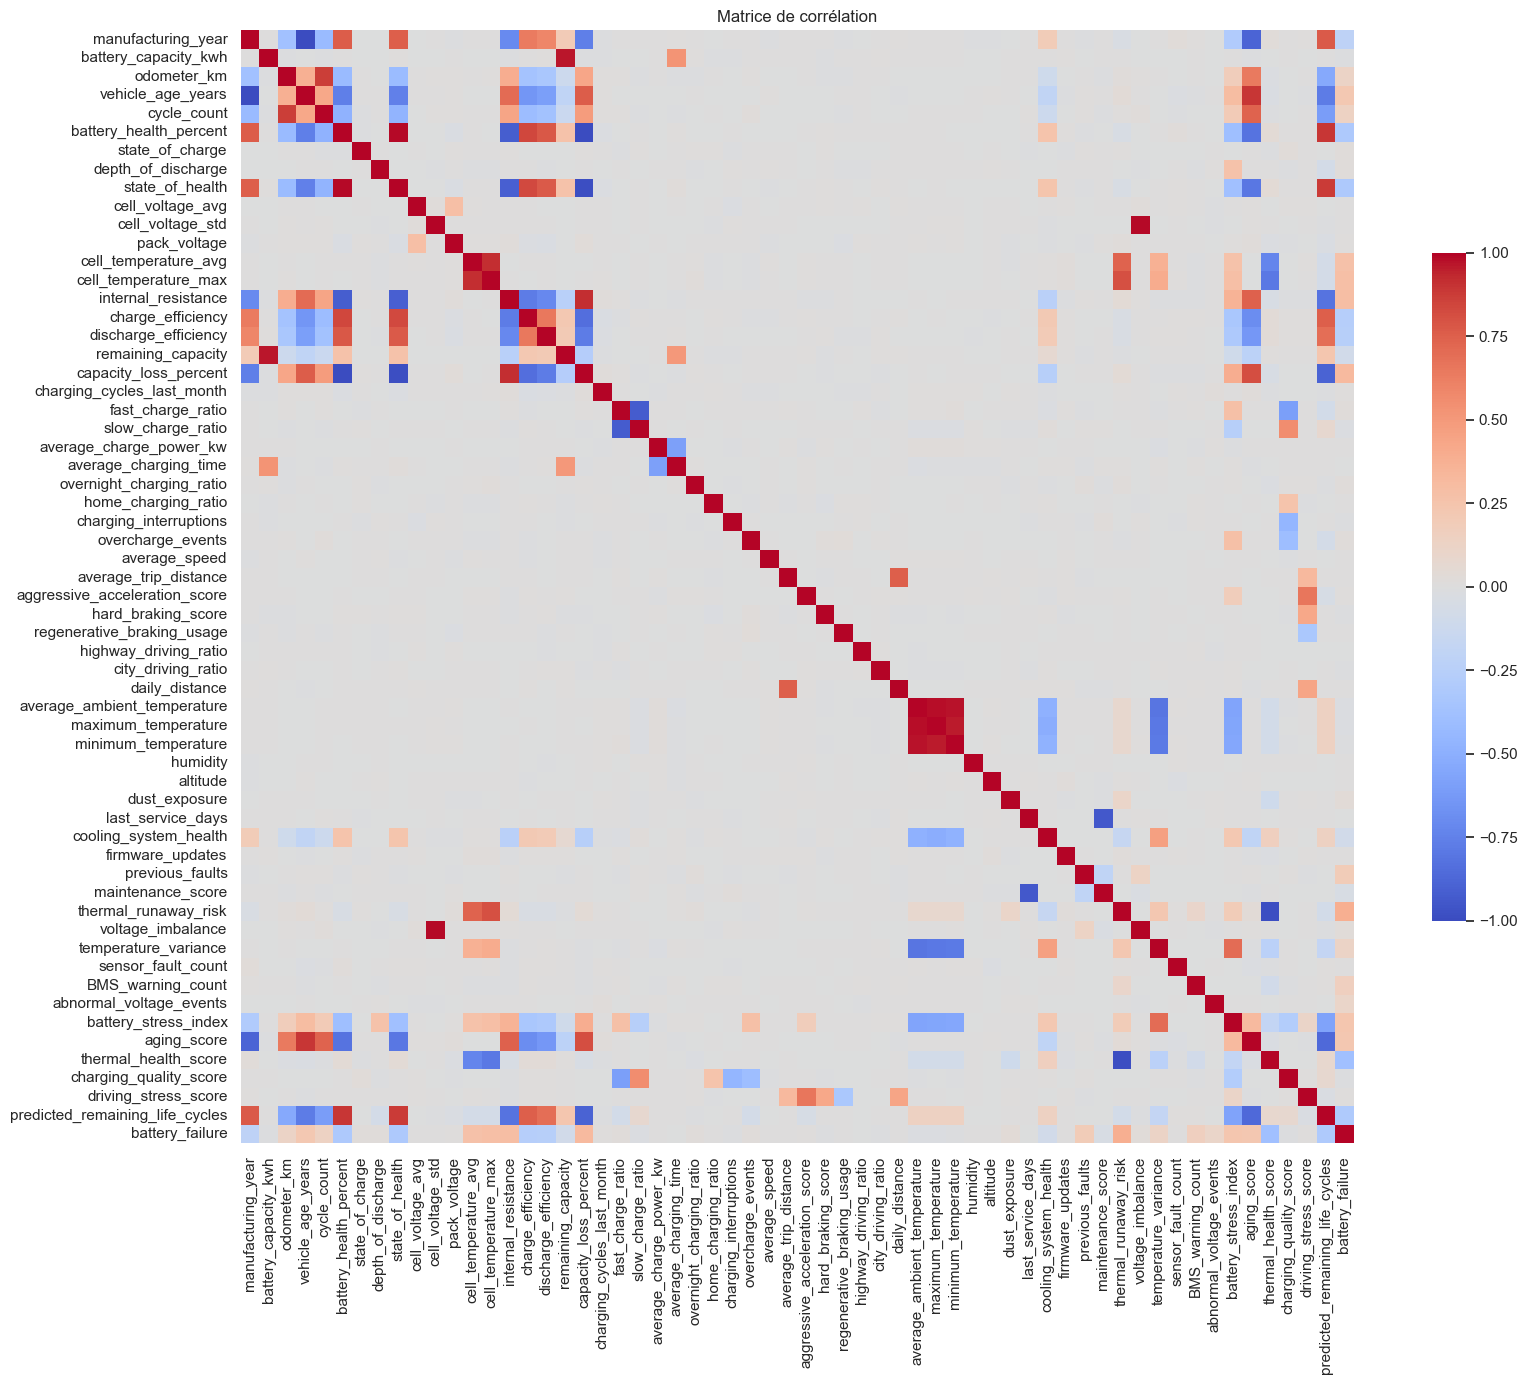

In [10]:
corr = df_quanti.corr()
plt.figure(figsize=(18, 14))
sns.heatmap(corr, cmap='coolwarm', center=0, vmin=-1, vmax=1, square=True,
            cbar_kws={'shrink': .6})
plt.title('Matrice de corrélation')
plt.tight_layout()
plt.show()

In [11]:
pairs = (corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
             .stack().sort_values(key=abs, ascending=False))
pairs.head(15)

battery_health_percent       capacity_loss_percent   -1.000000
manufacturing_year           vehicle_age_years       -0.995283
state_of_health              capacity_loss_percent   -0.989765
battery_health_percent       state_of_health          0.989756
cell_voltage_std             voltage_imbalance        0.987412
thermal_runaway_risk         thermal_health_score    -0.986754
average_ambient_temperature  maximum_temperature      0.979392
                             minimum_temperature      0.973845
battery_capacity_kwh         remaining_capacity       0.960995
maximum_temperature          minimum_temperature      0.953562
last_service_days            maintenance_score       -0.939095
fast_charge_ratio            slow_charge_ratio       -0.925611
battery_health_percent       internal_resistance     -0.918540
internal_resistance          capacity_loss_percent    0.918181
cell_temperature_avg         cell_temperature_max     0.914794
dtype: float64

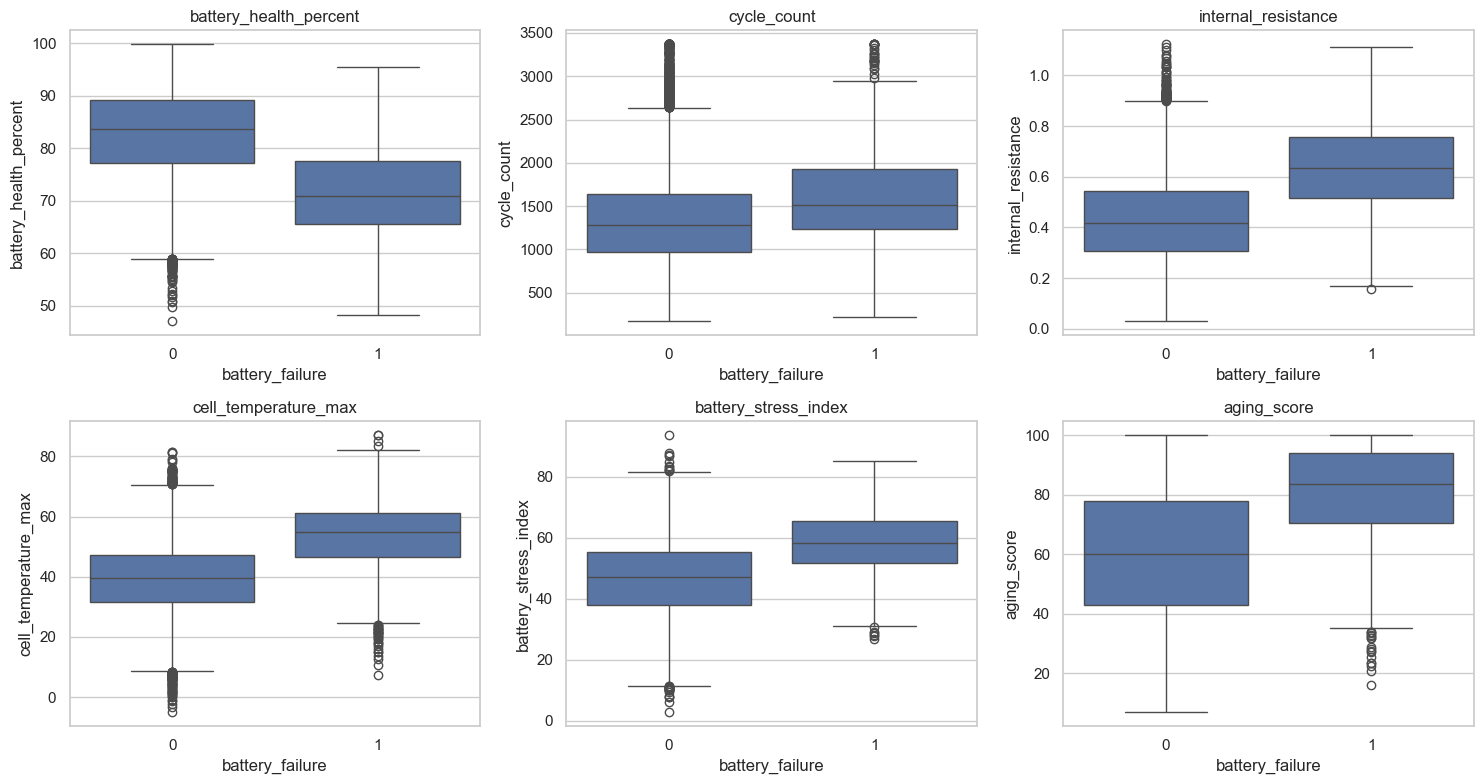

In [12]:
cibles = ['battery_health_percent', 'cycle_count', 'internal_resistance',
          'cell_temperature_max', 'battery_stress_index', 'aging_score']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, cibles):
    sns.boxplot(data=data, x='battery_failure', y=col, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

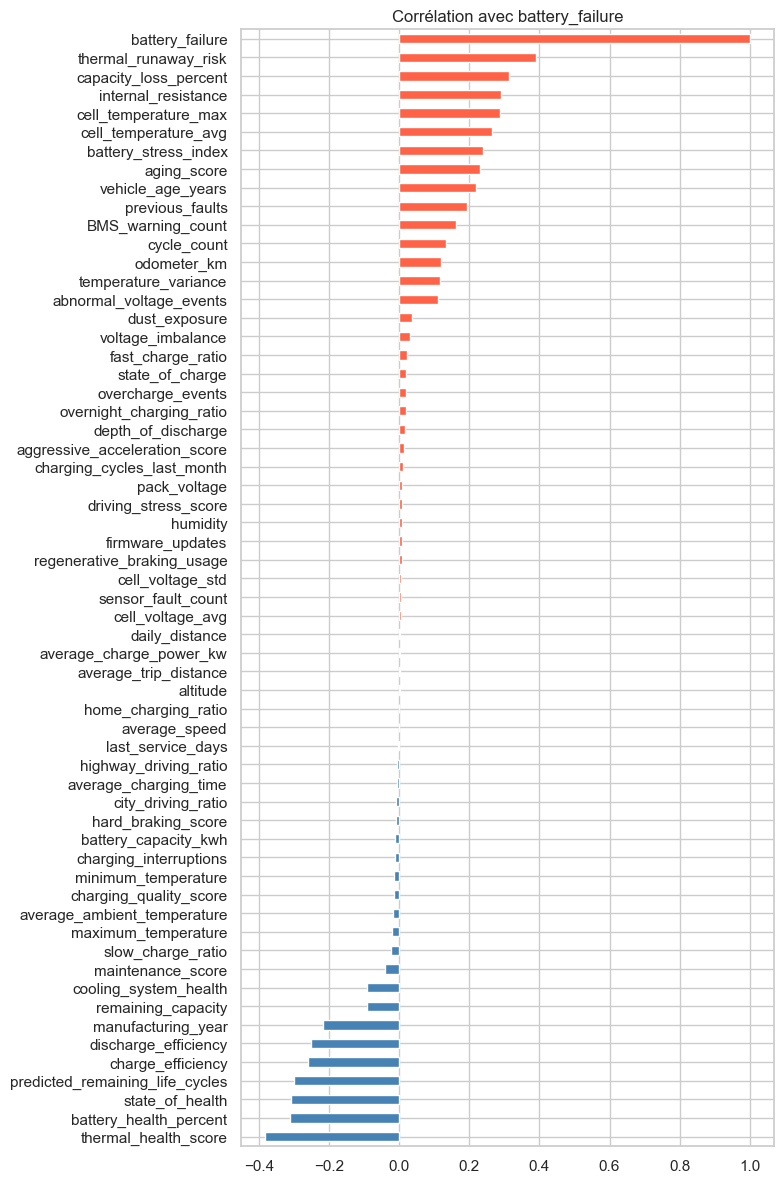

In [13]:
corr_target = (df_quanti.assign(target=data['battery_failure'].astype(int))
               .corr()['target'].drop('target').sort_values())

plt.figure(figsize=(8, 12))
corr_target.plot(kind='barh', color=np.where(corr_target > 0, 'tomato', 'steelblue'))
plt.title('Corrélation avec battery_failure')
plt.tight_layout()
plt.show()

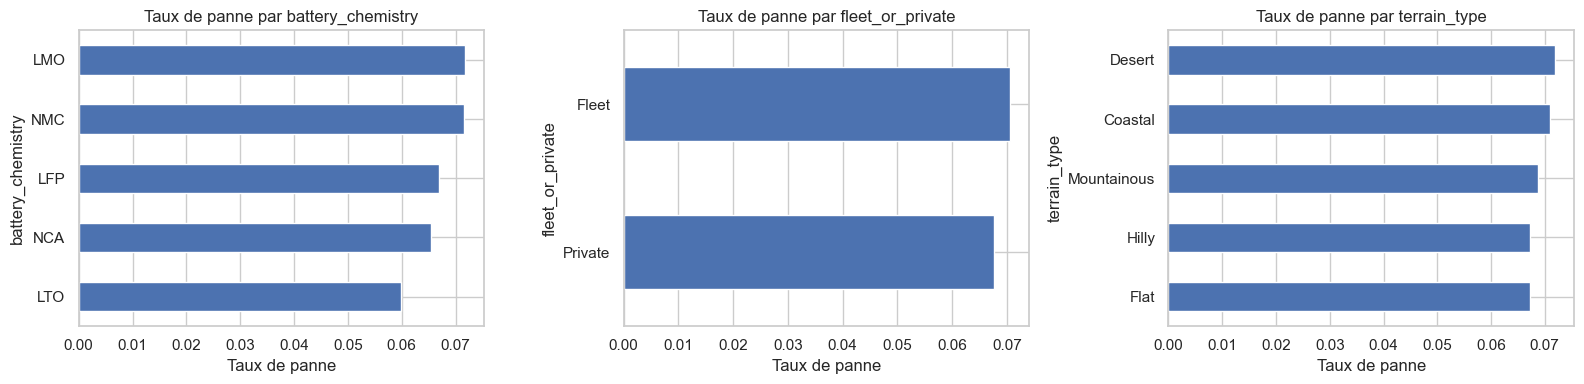

In [14]:
fail = data.assign(f=data['battery_failure'].astype(int))
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ['battery_chemistry', 'fleet_or_private', 'terrain_type']):
    fail.groupby(col)['f'].mean().sort_values().plot(kind='barh', ax=ax)
    ax.set_title(f'Taux de panne par {col}')
    ax.set_xlabel('Taux de panne')
plt.tight_layout()
plt.show()

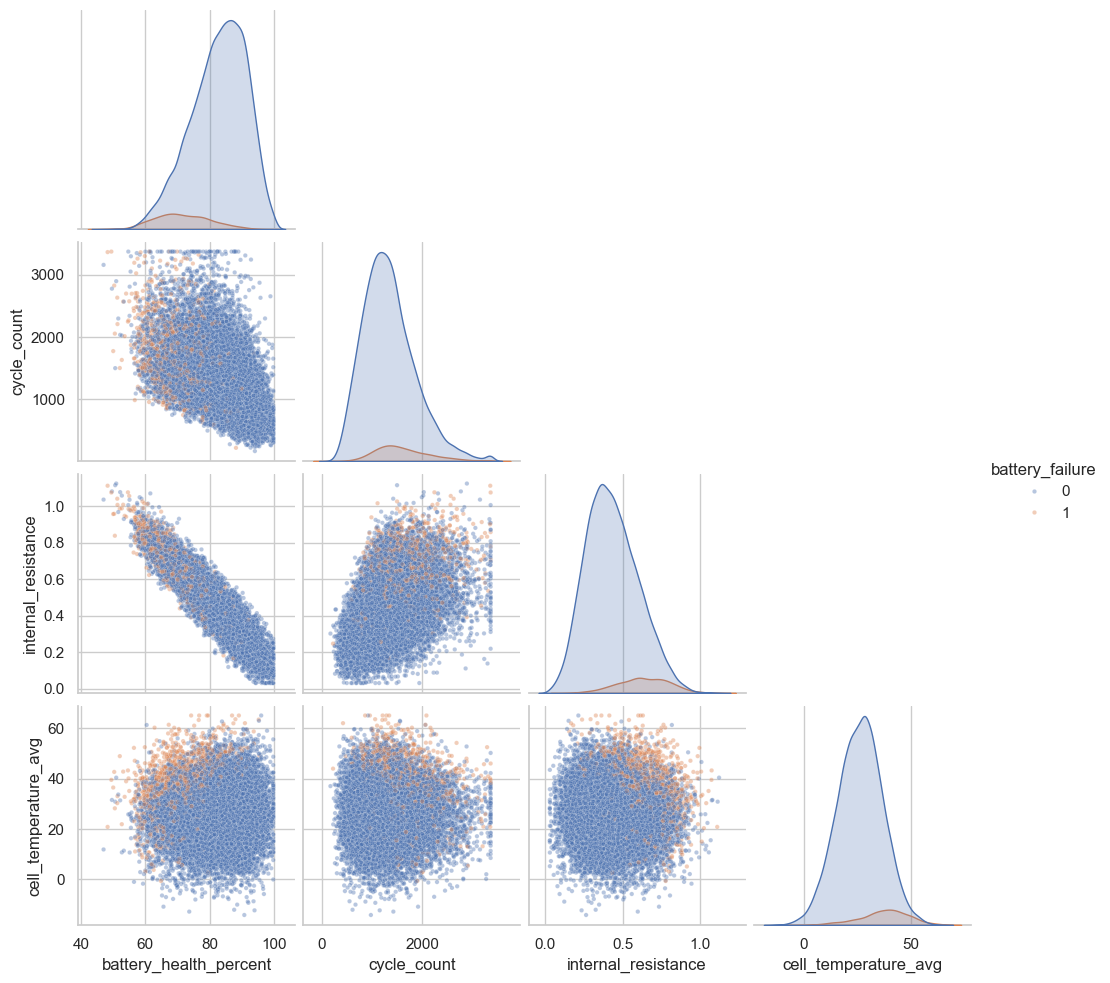

In [15]:
sns.pairplot(data[['battery_health_percent', 'cycle_count', 'internal_resistance',
                   'cell_temperature_avg', 'battery_failure']].dropna(),
             hue='battery_failure', corner=True, plot_kws={'alpha': 0.4, 's': 10})
plt.show()